# Caso de Estudio A — De viajes a decisiones de marketing
## Cyclistic: ¿cómo convertir comportamiento en crecimiento sostenible?

**Certificado Profesional de Google Data Analytics · Portfolio profesional**  
**Autor:** José Aníbal Modad  
**Fecha:** Agosto 2026  
**Herramientas:** Python · Pandas · NumPy · Matplotlib · Seaborn · SQL (opcional)

---

> **Historia que guía el análisis**
>
> Cyclistic no necesita solamente saber cuántas bicicletas utiliza cada segmento. Necesita entender **qué comportamiento distingue a un usuario ocasional de un miembro anual**, qué señales pueden utilizarse para reconocer oportunidades de conversión y cómo traducir esos patrones en decisiones de marketing.
>
> Este notebook sigue el ciclo analítico del Certificado Profesional de Google Data Analytics: **Ask → Prepare → Process → Analyze → Share → Act**, incorporando una narrativa orientada a negocio y una lectura ejecutiva de cada hallazgo.

### Pregunta central
**¿Cómo utilizan las bicicletas de Cyclistic de manera diferente los miembros anuales y los usuarios ocasionales, y qué implicancias tiene esa diferencia para una estrategia de conversión?**

### Resultado esperado
Transformar aproximadamente 12 meses de viajes en:
1. datos confiables y auditables;
2. patrones de comportamiento comparables;
3. hallazgos accionables;
4. recomendaciones de marketing medibles.

> **Nota metodológica:** este análisis trabaja con datos agregados de viajes. No identifica personas individuales ni permite calcular directamente frecuencia por cliente único. Las recomendaciones, por tanto, se basan en **comportamiento de viajes**, no en historial individual de clientes.


# 1. ASK — Preguntar
## 1.1 Contexto de negocio

Cyclistic es un sistema de bicicletas compartidas de Chicago. El desafío de negocio parte de una premisa económica: **los miembros anuales son más rentables que los usuarios ocasionales**. El área de marketing quiere identificar oportunidades para aumentar la conversión de usuarios ocasionales hacia membresías anuales.

La pregunta no es simplemente *“¿quién realiza más viajes?”*. La pregunta de negocio es:

> **¿Qué diferencias de comportamiento pueden convertirse en señales útiles para diseñar una estrategia de adquisición y conversión?**

### Stakeholders
- **Dirección de Marketing:** necesita decisiones claras y accionables.
- **Equipo de Marketing Analytics:** necesita evidencia reproducible.
- **Equipo Ejecutivo:** necesita priorización, impacto esperado y métricas de seguimiento.

### Hipótesis iniciales — a validar, no a asumir
- Los miembros podrían mostrar un comportamiento más **rutinario y recurrente**.
- Los usuarios ocasionales podrían concentrar más actividad en **fines de semana y períodos de ocio**.
- La **duración** de los viajes podría diferenciar la intensidad de uso entre segmentos.
- Una combinación de **día de la semana + duración + volumen** podría revelar momentos adecuados para campañas de conversión.

Estas hipótesis se utilizarán como guía. **Los datos decidirán si se sostienen o se rechazan.**


## 1.2 Alcance y definición de éxito

**Período analizado:** agosto de 2025 → julio de 2026.  
**Unidad de análisis:** un viaje (`ride_id`).  
**Segmento:** `member` vs. `casual`.

### Criterio de éxito analítico
El análisis será considerado útil si permite responder, con evidencia:

1. ¿Qué segmento concentra mayor volumen?
2. ¿Cuál presenta viajes más largos?
3. ¿Cuándo utiliza la bicicleta cada segmento?
4. ¿Qué patrones son suficientemente claros como para orientar una acción de marketing?
5. ¿Cómo mediríamos si una campaña posterior realmente funciona?

### Criterio de éxito de negocio
La salida final no será una lista de gráficos. Será una **hipótesis de crecimiento medible**: segmento → comportamiento → oportunidad → acción → KPI.


# 2. PREPARE — Preparar
## 2.1 Fuentes y estructura

Se utilizan 12 archivos CSV mensuales de viajes, almacenados localmente en `capstone_archivos/`.

El primer objetivo es verificar antes de combinar:
- cantidad de archivos;
- estructura de columnas;
- período temporal;
- categorías de usuario;
- volumen aproximado;
- posibles inconsistencias de nomenclatura.

Esto evita el error clásico de comenzar a analizar antes de saber **qué datos tenemos realmente**.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ruta_datos = "capstone_archivos"
archivos_csv = sorted(glob.glob(os.path.join(ruta_datos, "*.csv")))

print(f"Archivos CSV encontrados: {len(archivos_csv)}")
for i, archivo in enumerate(archivos_csv, 1):
    print(f"{i:02d}. {os.path.basename(archivo)}")

if len(archivos_csv) != 12:
    print("\nADVERTENCIA: se esperaban 12 archivos mensuales.")


Archivos CSV encontrados: 12
01. 202508-divvy-tripdata.csv
02. 202509-divvy-tripdata.csv
03. 202510-divvy-tripdata.csv
04. 202511-divvy-tripdata.csv
05. 202512-divvy-tripdata.csv
06. 202601-divvy-tripdata.csv
07. 202602-divvy-tripdata.csv
08. 202603-divvy-tripdata.csv
09. 202604-divvy-tripdata.csv
10. 202605-divvy-tripdata.csv
11. 202606-divvy-tripdata.csv
12. 202607-divvy-tripdata.csv


In [2]:
# Auditoría de esquema y período por archivo
resumen_archivos = []

for archivo in archivos_csv:
    df_tmp = pd.read_csv(
        archivo,
        usecols=["started_at", "ended_at", "member_casual"],
        parse_dates=["started_at", "ended_at"]
    )

    resumen_archivos.append({
        "archivo": os.path.basename(archivo),
        "filas": len(df_tmp),
        "fecha_min": df_tmp["started_at"].min(),
        "fecha_max": df_tmp["started_at"].max(),
        "usuarios": ", ".join(sorted(df_tmp["member_casual"].dropna().astype(str).unique()))
    })

auditoria_archivos = pd.DataFrame(resumen_archivos)
display(auditoria_archivos)

print(f"Filas teóricas a consolidar: {auditoria_archivos['filas'].sum():,}")


,archivo,filas,fecha_min,fecha_max,usuarios
0,202508-divvy-tripdata.csv,790177,2025-07-30 23:35:27.719,2025-08-31 23:55:36.521,"casual, member"
1,202509-divvy-tripdata.csv,714759,2025-08-30 23:10:32.607,2025-09-30 23:57:30.490,"casual, member"
2,202510-divvy-tripdata.csv,646039,2025-09-30 08:37:53.455,2025-10-31 23:56:47.949,"casual, member"
3,202511-divvy-tripdata.csv,356628,2025-10-31 01:24:38.549,2025-11-30 23:51:43.800,"casual, member"
4,202512-divvy-tripdata.csv,140534,2025-11-30 16:02:08.178,2025-12-31 23:53:24.274,"casual, member"
5,202601-divvy-tripdata.csv,137787,2025-12-31 10:30:49.482,2026-01-31 23:56:54.069,"casual, member"
6,202602-divvy-tripdata.csv,201450,2026-01-31 11:08:07.830,2026-02-28 23:57:54.093,"casual, member"
7,202603-divvy-tripdata.csv,317037,2026-02-28 10:48:22.074,2026-03-31 23:55:56.848,"casual, member"
8,202604-divvy-tripdata.csv,448252,2026-04-01 00:01:42.066,2026-04-30 23:58:56.151,"casual, member"
9,202605-divvy-tripdata.csv,653704,2026-04-30 00:24:47.685,2026-05-31 23:57:08.778,"casual, member"


Filas teóricas a consolidar: 6,037,968


### Control de calidad: ROCCC

| Criterio | Evaluación |
|---|---|
| **Reliable** | Datos operativos de viajes, con marcas temporales y variables de uso. |
| **Original** | Fuente primaria publicada para el caso de estudio. |
| **Comprehensive** | 12 meses consecutivos y múltiples dimensiones del viaje. |
| **Current** | El período llega hasta julio de 2026 dentro del alcance de este proyecto. |
| **Cited** | La fuente y las decisiones de transformación deben documentarse en el proyecto. |

### Limitaciones conocidas
- No existe un identificador persistente de cliente.
- No podemos medir usuarios únicos ocasionales.
- No podemos atribuir directamente rentabilidad individual.
- Los datos describen **comportamiento observado de viajes**, no motivaciones declaradas por clientes.

Estas limitaciones no invalidan el análisis; delimitan correctamente lo que podemos afirmar.


# 3. PROCESS — Procesar
## 3.1 Consolidación

Una vez validada la estructura, los 12 archivos se combinan en un único DataFrame maestro.

**Principio:** primero conservar y auditar; después transformar.


In [3]:
lista_dataframes = []

for archivo in archivos_csv:
    nombre_mes = os.path.basename(archivo)[:6]
    df_mes = pd.read_csv(
        archivo,
        parse_dates=["started_at", "ended_at"]
    )
    print(f"{nombre_mes}: {len(df_mes):,} filas")
    lista_dataframes.append(df_mes)

df_consolidado = pd.concat(lista_dataframes, ignore_index=True)

print("-" * 70)
print(f"Filas consolidadas: {len(df_consolidado):,}")
print(f"Columnas: {df_consolidado.shape[1]}")


202508: 790,177 filas
202509: 714,759 filas
202510: 646,039 filas
202511: 356,628 filas
202512: 140,534 filas
202601: 137,787 filas
202602: 201,450 filas
202603: 317,037 filas
202604: 448,252 filas
202605: 653,704 filas
202606: 762,550 filas
202607: 869,051 filas
----------------------------------------------------------------------
Filas consolidadas: 6,037,968
Columnas: 13


In [4]:
carpeta_backups = "backups"
os.makedirs(carpeta_backups, exist_ok=True)

archivo_respaldo_seguro = os.path.join(carpeta_backups, "202508_202607_divvy_tripdata_consolidado_raw.csv")

df_consolidado.to_csv(archivo_respaldo_seguro, index=False)


print(f"Archivo guardado en: {archivo_respaldo_seguro}")
print(f"Tamaño: {os.path.getsize(archivo_respaldo_seguro) / (1024 * 1024):.2f} MB")

Archivo guardado en: backups/202508_202607_divvy_tripdata_consolidado_raw.csv
Tamaño: 1051.57 MB


In [5]:
from sqlalchemy import create_engine
from dotenv import load_dotenv


load_dotenv()

USUARIO = os.getenv("DB_USER")
PASSWORD = os.getenv("DB_PASSWORD")
HOST = os.getenv("DB_HOST")
PUERTO = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME") 


conexion_url = f"postgresql://{USUARIO}:{PASSWORD}@{HOST}:{PUERTO}/{DB_NAME}"


try:
    engine = create_engine(conexion_url)
    
    nombre_tabla = "tripdata_raw"
    print(f"Exportando {df_consolidado.shape[0]:,} filas a la tabla '{nombre_tabla}'...")

    
    df_consolidado.to_sql(
        name=nombre_tabla,
        con=engine,
        if_exists="replace",  
        index=False,          
        chunksize=100000     
    )
    
    print(f"Los datos se guardaron en la tabla: {nombre_tabla}")

except Exception as e:
    print("\n[Error de Conexión/Exportación]:")
    print(e)

Exportando 6,037,968 filas a la tabla 'tripdata_raw'...
Los datos se guardaron en la tabla: tripdata_raw


In [6]:
# Perfil inicial de calidad
perfil_inicial = pd.DataFrame({
    "columna": df_consolidado.columns,
    "tipo": df_consolidado.dtypes.astype(str).values,
    "nulos": df_consolidado.isna().sum().values,
    "nulos_%": (df_consolidado.isna().mean().values * 100),
    "valores_unicos": [df_consolidado[c].nunique(dropna=True) for c in df_consolidado.columns]
}).sort_values("nulos_%", ascending=False)

display(perfil_inicial)


,columna,tipo,nulos,nulos_%,valores_unicos
6,end_station_name,str,1336777,22.14,2016
7,end_station_id,str,1336777,22.14,2022
5,start_station_id,str,1273200,21.09,1986
4,start_station_name,str,1273200,21.09,1980
10,end_lat,float64,5436,0.09,2179
11,end_lng,float64,5436,0.09,2176
2,started_at,datetime64[us],0,0.00,6036660
1,rideable_type,str,0,0.00,2
0,ride_id,str,0,0.00,6037933
3,ended_at,datetime64[us],0,0.00,6034854


## 3.2 Duplicados: distinguir error técnico de comportamiento

Se audita `ride_id` porque funciona como identificador de la transacción.

La regla de calidad es sencilla:

> **Un viaje no debe contar dos veces.**

En la auditoría original se encontraron **35 `ride_id` duplicados**, equivalentes a 70 filas. La inspección mostró que los duplicados corresponden a viajes que cruzan el límite entre abril y mayo de 2026.

**Decisión:** conservar una sola fila por `ride_id`, evitando inflar artificialmente volumen y duración acumulada.


In [7]:
duplicados_id = df_consolidado.duplicated(subset=["ride_id"], keep=False)
ids_repetidos = df_consolidado.loc[duplicados_id, "ride_id"].unique()

print(f"Ride IDs duplicados: {len(ids_repetidos):,}")
print(f"Filas involucradas: {duplicados_id.sum():,}")

if len(ids_repetidos) > 0:
    columnas_inspeccion = [
        "ride_id", "rideable_type", "started_at",
        "ended_at", "member_casual"
    ]
    display(
        df_consolidado[
            df_consolidado["ride_id"].isin(ids_repetidos)
        ][columnas_inspeccion].sort_values("ride_id").head(70)
    )


Ride IDs duplicados: 35
Filas involucradas: 70


,ride_id,rideable_type,started_at,ended_at,member_casual
3548524,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,member
4289378,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,member
3669856,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,member
4012437,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,member
3489083,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,casual
...,...,...,...,...,...
4030739,E87E123751FA42E1,classic_bike,2026-04-30 17:27:25.585,2026-05-01 18:27:01.264,casual
3358204,E923A7ACDD4A9293,classic_bike,2026-04-30 23:58:06.960,2026-05-01 00:00:34.820,casual
4206315,E923A7ACDD4A9293,classic_bike,2026-04-30 23:58:06.960,2026-05-01 00:00:34.820,casual
3455842,EAB7C279D822C763,classic_bike,2026-04-30 23:58:36.620,2026-05-01 00:02:45.401,member


In [8]:
filas_antes = len(df_consolidado)

df_consolidado = df_consolidado.drop_duplicates(
    subset=["ride_id"],
    keep="first"
).copy()

print(f"Filas antes: {filas_antes:,}")
print(f"Filas después: {len(df_consolidado):,}")
print(f"Duplicados eliminados: {filas_antes - len(df_consolidado):,}")
print(f"Duplicados restantes: {df_consolidado.duplicated('ride_id').sum():,}")


Filas antes: 6,037,968
Filas después: 6,037,933
Duplicados eliminados: 35
Duplicados restantes: 0


## 3.3 Valores faltantes: no todo `NaN` es un error

Un enfoque profesional de limpieza no consiste en eliminar automáticamente todos los nulos.

Primero preguntamos:

**¿La ausencia representa una falla de captura o una característica real del producto?**

En este dataset, los viajes de bicicletas eléctricas pueden comenzar o terminar fuera de una estación física. Por ello, la ausencia de nombre de estación no debe interpretarse automáticamente como un registro inválido.

En cambio, la ausencia simultánea de coordenadas de destino en viajes clásicos impide utilizar ese viaje para análisis espacial y temporal completo. En la auditoría original se identificaron **5.430 registros** con ese patrón.

**Decisión:** eliminar esos registros específicos, documentando la pérdida de información.


In [9]:
df_coordenadas_nulas = df_consolidado[
    df_consolidado["end_lat"].isna() | df_consolidado["end_lng"].isna()
]

print(f"Filas con coordenadas finales faltantes: {len(df_coordenadas_nulas):,}")

if len(df_coordenadas_nulas):
    display(
        df_coordenadas_nulas[
            ["rideable_type", "member_casual", "end_station_name",
             "end_station_id", "end_lat", "end_lng"]
        ].isna().sum().to_frame("nulos")
    )
    print("\nDistribución por bicicleta:")
    display(df_coordenadas_nulas["rideable_type"].value_counts(dropna=False))
    print("\nDistribución por segmento:")
    display(df_coordenadas_nulas["member_casual"].value_counts(dropna=False))


Filas con coordenadas finales faltantes: 5,430


,nulos
rideable_type,0
member_casual,0
end_station_name,5430
end_station_id,5430
end_lat,5430
end_lng,5430



Distribución por bicicleta:


rideable_type
classic_bike    5430
Name: count, dtype: int64


Distribución por segmento:


member_casual
casual    4390
member    1040
Name: count, dtype: int64

In [10]:
filas_antes_geo = len(df_consolidado)

df_consolidado = df_consolidado.dropna(
    subset=["end_lat", "end_lng"]
).copy()

print(f"Registros removidos por falta de coordenadas finales: "
      f"{filas_antes_geo - len(df_consolidado):,}")
print(f"Universo actual: {len(df_consolidado):,}")


Registros removidos por falta de coordenadas finales: 5,430
Universo actual: 6,032,503


## 3.4 Imputación categórica de estaciones

Después del filtrado geográfico permanecen ausencias de estación, principalmente asociadas al funcionamiento *free-floating* de bicicletas eléctricas.

Para no confundir **“sin estación”** con **“dato perdido”**, se utiliza una categoría explícita:

- `On-Street Checkout`
- `On-Street Return`

Esto conserva los viajes y hace visible la naturaleza del dato en lugar de ocultarla con un valor genérico.


In [11]:
df_consolidado["start_station_name"] = (
    df_consolidado["start_station_name"].fillna("On-Street Checkout")
)
df_consolidado["start_station_id"] = (
    df_consolidado["start_station_id"].fillna("On-Street Checkout")
)
df_consolidado["end_station_name"] = (
    df_consolidado["end_station_name"].fillna("On-Street Return")
)
df_consolidado["end_station_id"] = (
    df_consolidado["end_station_id"].fillna("On-Street Return")
)

print("Nulos en nombres de estación:")
display(df_consolidado[["start_station_name", "end_station_name"]].isna().sum())


Nulos en nombres de estación:


start_station_name    0
end_station_name      0
dtype: int64

## 3.5 Ingeniería de variables

Para pasar de datos operativos a variables analíticas se crean:

- `ride_length`: duración del viaje en minutos.
- `day_of_week`: día de la semana.
- `day_name`: etiqueta legible.
- `month`: mes calendario.
- `hour`: hora de inicio.

Estas variables permiten comparar comportamiento temporal sin necesidad de datos personales.


In [12]:
df_consolidado["ride_length"] = (
    df_consolidado["ended_at"] - df_consolidado["started_at"]
).dt.total_seconds() / 60

df_consolidado["day_of_week"] = df_consolidado["started_at"].dt.dayofweek

dias_nombre = {
    0: "Lunes", 1: "Martes", 2: "Miércoles",
    3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"
}

df_consolidado["day_name"] = df_consolidado["day_of_week"].map(dias_nombre)
df_consolidado["month"] = df_consolidado["started_at"].dt.to_period("M").astype(str)
df_consolidado["hour"] = df_consolidado["started_at"].dt.hour

display(df_consolidado[
    ["started_at", "ended_at", "ride_length", "day_name", "month", "hour"]
].head())


,started_at,ended_at,ride_length,day_name,month,hour
0,2025-08-28 15:56:46.803,2025-08-28 16:11:54.890,15.13,Jueves,2025-08,15
1,2025-08-27 19:15:53.059,2025-08-27 19:34:13.683,18.34,Miércoles,2025-08,19
2,2025-08-27 20:27:31.394,2025-08-27 20:38:29.890,10.97,Miércoles,2025-08,20
3,2025-08-28 15:33:21.055,2025-08-28 15:39:58.052,6.62,Jueves,2025-08,15
4,2025-08-28 09:59:44.846,2025-08-28 10:11:17.343,11.54,Jueves,2025-08,9


## 3.6 Control de anomalías temporales

Un viaje con duración negativa o igual a cero es lógicamente imposible.

También se revisan los viajes inferiores a un minuto. En la auditoría original se encontraron:

- **29 viajes** con duración ≤ 0.
- **160.902 viajes** con duración entre 0 y <1 minuto.

Para este caso de estudio se adopta un umbral conservador de **1 minuto** para evitar que eventos operativos extremadamente breves distorsionen promedios y distribuciones.

> Importante: no se asigna una causa específica a esos viajes sin evidencia adicional. Se los trata como anomalías analíticas, no como robos, averías o cancelaciones confirmadas.


In [13]:
viajes_no_validos = (df_consolidado["ride_length"] <= 0).sum()
viajes_menor_minuto = (
    (df_consolidado["ride_length"] > 0) &
    (df_consolidado["ride_length"] < 1)
).sum()

print(f"Duración <= 0: {viajes_no_validos:,}")
print(f"Duración entre 0 y <1 minuto: {viajes_menor_minuto:,}")


Duración <= 0: 29
Duración entre 0 y <1 minuto: 160,902


In [14]:
filas_antes_tiempo = len(df_consolidado)

df_consolidado = df_consolidado[
    df_consolidado["ride_length"] >= 1
].copy()

print(f"Registros eliminados por criterio temporal: "
      f"{filas_antes_tiempo - len(df_consolidado):,}")
print(f"UNIVERSO FINAL PARA ANÁLISIS: {len(df_consolidado):,}")


Registros eliminados por criterio temporal: 160,931
UNIVERSO FINAL PARA ANÁLISIS: 5,871,572


## 3.7 Data Quality Gate — antes de analizar

No avanzamos a la fase de análisis hasta comprobar cuatro condiciones:

1. `ride_id` único.
2. Duración ≥ 1 minuto.
3. Fechas válidas.
4. Segmentos válidos (`member`, `casual`).

Este control convierte la limpieza en un **punto de decisión auditable**, no en una colección de transformaciones aisladas.


In [15]:
quality_checks = {
    "ride_id duplicados": df_consolidado["ride_id"].duplicated().sum(),
    "duración < 1 minuto": (df_consolidado["ride_length"] < 1).sum(),
    "started_at nulo": df_consolidado["started_at"].isna().sum(),
    "ended_at nulo": df_consolidado["ended_at"].isna().sum(),
    "segmentos inválidos": (~df_consolidado["member_casual"].isin(["member", "casual"])).sum(),
}

quality_report = pd.DataFrame(
    {"control": quality_checks.keys(), "resultado": quality_checks.values()}
)

display(quality_report)

if quality_report["resultado"].sum() == 0:
    print("✓ DATA QUALITY GATE SUPERADO")
else:
    print("Revisar controles antes de continuar.")


,control,resultado
0,ride_id duplicados,0
1,duración < 1 minuto,0
2,started_at nulo,0
3,ended_at nulo,0
4,segmentos inválidos,0


✓ DATA QUALITY GATE SUPERADO


In [16]:
nombre_backup_limpio = "202508_202607-divvy-tripdata-cleaned.parquet"
ruta_parquet = os.path.join("backups", nombre_backup_limpio)


df_consolidado.to_parquet(ruta_parquet, index=False)

print(f"Archivo guardado exitosamente en: {ruta_parquet}")
print(f"Tamaño optimizado en disco: {os.path.getsize(ruta_parquet) / (1024 * 1024):.2f} MB")

Archivo guardado exitosamente en: backups/202508_202607-divvy-tripdata-cleaned.parquet
Tamaño optimizado en disco: 288.49 MB


In [17]:
try:
    engine = create_engine(conexion_url)
    
    nombre_tabla = "tripdata_cleaned"
    print(f"Exportando {df_consolidado.shape[0]:,} filas a la tabla '{nombre_tabla}'...")

    
    df_consolidado.to_sql(
        name=nombre_tabla,
        con=engine,
        if_exists="replace",  
        index=False,          
        chunksize=100000     
    )
    
    print(f"Los datos se guardaron en la tabla: {nombre_tabla}")

except Exception as e:
    print("\n[Error de Conexión/Exportación]:")
    print(e)

Exportando 5,871,572 filas a la tabla 'tripdata_cleaned'...
Los datos se guardaron en la tabla: tripdata_cleaned


# 4. ANALYZE — Analizar
## 4.1 Del volumen al comportamiento

La primera capa responde **“cuánto”**.  
La segunda responde **“cómo”**.  
La tercera intenta responder **“cuándo aparece la oportunidad”**.

La segmentación `member` vs. `casual` será el eje narrativo de toda la fase.


In [18]:
df_analisis_global = (
    df_consolidado
    .groupby("member_casual")
    .agg(
        total_viajes=("ride_id", "count"),
        duracion_promedio_min=("ride_length", "mean"),
        duracion_mediana_min=("ride_length", "median"),
        duracion_maxima_min=("ride_length", "max")
    )
    .reset_index()
)

total_global_viajes = df_analisis_global["total_viajes"].sum()

df_analisis_global["participacion_%"] = (
    df_analisis_global["total_viajes"] / total_global_viajes * 100
)

display(df_analisis_global)


,member_casual,total_viajes,duracion_promedio_min,duracion_mediana_min,duracion_maxima_min,participacion_%
0,casual,2068819,18.99,11.48,"1,499.97",35.23
1,member,3802753,12.28,8.75,"1,499.96",64.77


### Lectura ejecutiva — Volumen

Esta tabla establece la línea base del negocio.

**Qué debemos buscar:** si un segmento concentra la mayoría del volumen, ese segmento representa la principal base de comportamiento actual. Pero volumen por sí solo **no equivale a oportunidad de conversión**.

La oportunidad aparecerá cuando combinemos volumen con intensidad y temporalidad.


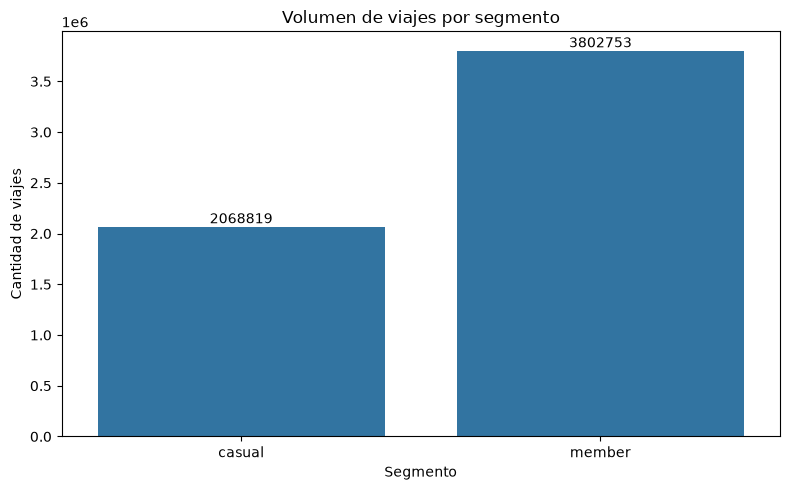

In [19]:
# Distribución de viajes por segmento
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_analisis_global,
    x="member_casual",
    y="total_viajes"
)

ax.set_title("Volumen de viajes por segmento")
ax.set_xlabel("Segmento")
ax.set_ylabel("Cantidad de viajes")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()


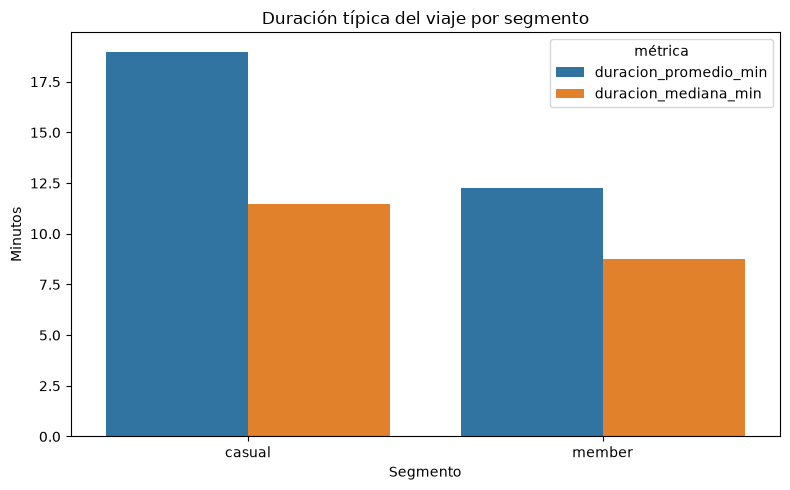

In [20]:
# Duración: media y mediana por segmento
fig, ax = plt.subplots(figsize=(8, 5))

metricas_duracion = df_analisis_global.melt(
    id_vars="member_casual",
    value_vars=["duracion_promedio_min", "duracion_mediana_min"],
    var_name="métrica",
    value_name="minutos"
)

sns.barplot(
    data=metricas_duracion,
    x="member_casual",
    y="minutos",
    hue="métrica",
    ax=ax
)

ax.set_title("Duración típica del viaje por segmento")
ax.set_xlabel("Segmento")
ax.set_ylabel("Minutos")
plt.tight_layout()
plt.show()


## 4.2 ¿Cuándo ocurre la demanda?

Una estrategia de marketing efectiva no solo necesita saber **quién** es el segmento; necesita saber **cuándo** aparece su comportamiento.

Comparamos:
- volumen diario;
- duración media diaria;
- diferencia entre miembros y ocasionales.


In [21]:
df_semanal = (
    df_consolidado
    .groupby(["member_casual", "day_of_week", "day_name"])
    .agg(
        numero_de_viajes=("ride_id", "count"),
        duracion_promedio_min=("ride_length", "mean")
    )
    .reset_index()
    .sort_values(["member_casual", "day_of_week"])
)

display(df_semanal)


,member_casual,day_of_week,day_name,numero_de_viajes,duracion_promedio_min
0,casual,0,Lunes,235171,19.02
1,casual,1,Martes,229786,16.31
2,casual,2,Miércoles,237434,15.79
3,casual,3,Jueves,258262,16.47
4,casual,4,Viernes,327089,18.46
5,casual,5,Sábado,438643,21.53
6,casual,6,Domingo,342434,22.11
7,member,0,Lunes,527236,11.97
8,member,1,Martes,601391,11.81
9,member,2,Miércoles,610043,11.76


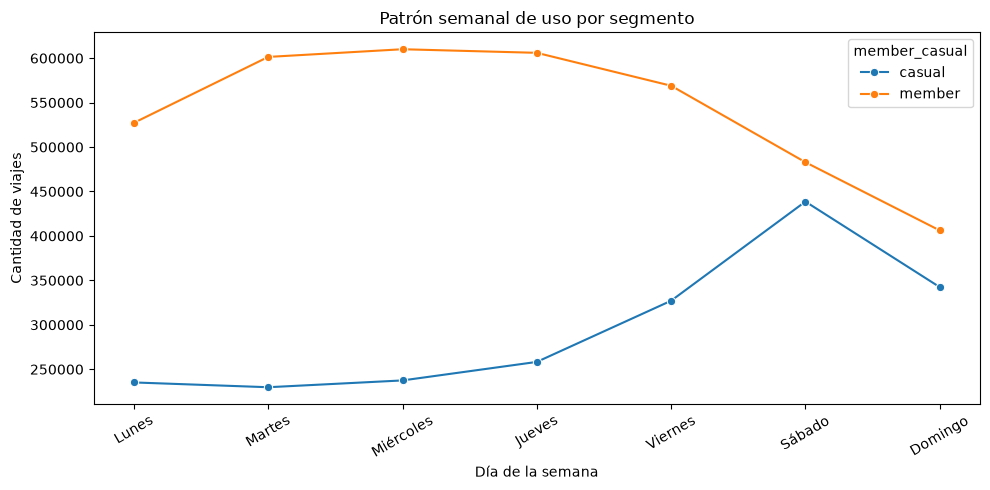

In [22]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_semanal,
    x="day_name",
    y="numero_de_viajes",
    hue="member_casual",
    marker="o"
)

plt.title("Patrón semanal de uso por segmento")
plt.xlabel("Día de la semana")
plt.ylabel("Cantidad de viajes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


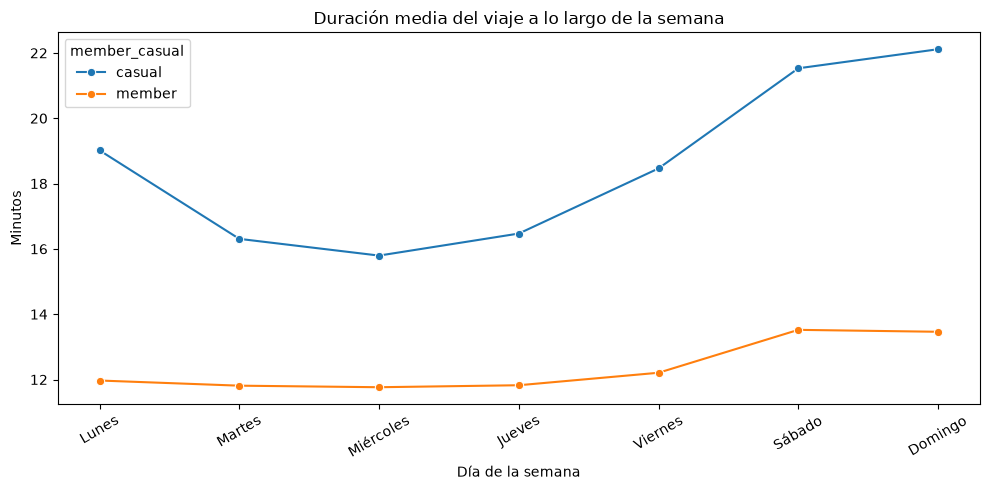

In [23]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_semanal,
    x="day_name",
    y="duracion_promedio_min",
    hue="member_casual",
    marker="o"
)

plt.title("Duración media del viaje a lo largo de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Minutos")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 4.3 Comportamiento horario

El horario ayuda a distinguir patrones compatibles con rutina diaria frente a patrones más recreativos.

No afirmaremos que un viaje es “laboral” o “recreativo” solo por su hora. En cambio, utilizaremos el lenguaje correcto:

- **patrón compatible con rutina**;
- **patrón compatible con ocio**;
- **señal que merece validación adicional**.


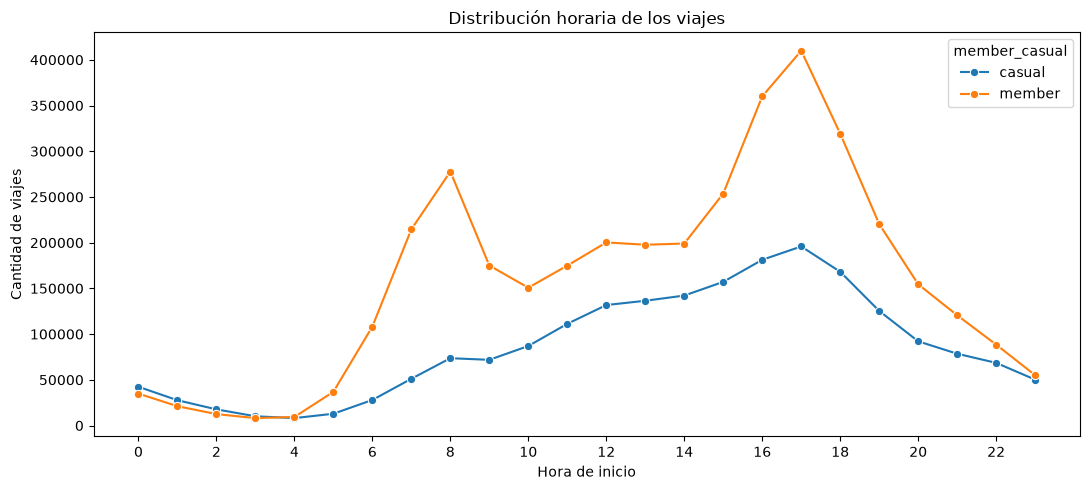

In [24]:
df_horario = (
    df_consolidado
    .groupby(["member_casual", "hour"])
    .size()
    .reset_index(name="viajes")
)

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=df_horario,
    x="hour",
    y="viajes",
    hue="member_casual",
    marker="o"
)

plt.title("Distribución horaria de los viajes")
plt.xlabel("Hora de inicio")
plt.ylabel("Cantidad de viajes")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


## 4.4 Estacionalidad mensual

Una campaña de conversión no debería planificarse solamente con promedios anuales. También importa saber si el comportamiento cambia con el calendario.

Se observa la evolución mensual para detectar:
- picos;
- valles;
- divergencias entre segmentos;
- períodos adecuados para experimentación.


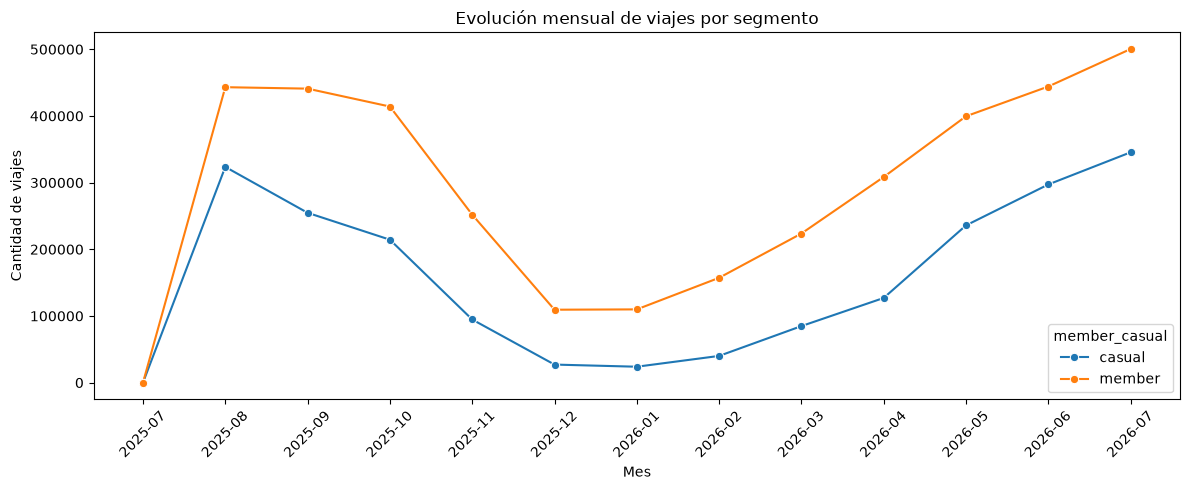

In [25]:
df_mensual = (
    df_consolidado
    .groupby(["month", "member_casual"])
    .agg(
        viajes=("ride_id", "count"),
        duracion_promedio_min=("ride_length", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_mensual,
    x="month",
    y="viajes",
    hue="member_casual",
    marker="o"
)

plt.title("Evolución mensual de viajes por segmento")
plt.xlabel("Mes")
plt.ylabel("Cantidad de viajes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 5. SHARE — Compartir
## 5.1 Storytelling ejecutivo

### La historia en una frase

> **Los dos segmentos utilizan el mismo producto, pero no necesariamente tienen la misma relación con él. La oportunidad de marketing está en identificar los comportamientos que se acercan al patrón de membresía y convertirlos en momentos de contacto relevantes.**

### Tres capas del hallazgo

**1 — Escala:**  
El volumen muestra qué segmento representa una parte relevante del uso actual.

**2 — Intensidad:**  
La duración permite saber si los viajes de un segmento son, en promedio, más extensos.

**3 — Momento:**  
Los patrones por día, hora y mes muestran cuándo tiene sentido activar una propuesta.

### Lo que NO debemos afirmar
- Que una mayor duración demuestra mayor rentabilidad.
- Que un día concreto significa necesariamente ocio o trabajo.
- Que un viaje representa a una persona única.
- Que una correlación observada implica causalidad.

Esta disciplina narrativa es tan importante como el cálculo: **un buen analista distingue dato, inferencia e hipótesis.**


In [26]:
# Tabla ejecutiva final
tabla_ejecutiva = df_analisis_global.copy()

tabla_ejecutiva["participacion_%"] = tabla_ejecutiva["participacion_%"].round(1)
tabla_ejecutiva["duracion_promedio_min"] = tabla_ejecutiva["duracion_promedio_min"].round(1)
tabla_ejecutiva["duracion_mediana_min"] = tabla_ejecutiva["duracion_mediana_min"].round(1)

display(
    tabla_ejecutiva[
        [
            "member_casual",
            "total_viajes",
            "participacion_%",
            "duracion_promedio_min",
            "duracion_mediana_min",
            "duracion_maxima_min"
        ]
    ]
)


,member_casual,total_viajes,participacion_%,duracion_promedio_min,duracion_mediana_min,duracion_maxima_min
0,casual,2068819,35.20,19.00,11.50,"1,499.97"
1,member,3802753,64.80,12.30,8.80,"1,499.96"


## 5.2 De hallazgo a insight

Un **hallazgo** describe lo que muestran los datos.

Un **insight** agrega significado de negocio.

La estructura recomendada para presentar cada insight es:

> **Dato → Diferencia → Interpretación prudente → Oportunidad**

Ejemplo de redacción profesional:

> “El segmento X concentra Y% de los viajes. Además, presenta una duración media de Z minutos frente a W del segmento contrario. Esto indica una diferencia de intensidad de uso que puede utilizarse como señal de segmentación. La siguiente etapa debería validar si este patrón se asocia con mayor propensión a contratar una membresía.”

La cifra exacta debe provenir de la tabla ejecutiva generada por el notebook; nunca debe escribirse de memoria.


# 6. ACT — Actuar
## 6.1 Recomendaciones de marketing

### Recomendación 1 — Segmentación por comportamiento
Crear campañas específicas para usuarios ocasionales cuyos patrones de uso se aproximen a los comportamientos observados en miembros.

**Por qué:** evita tratar a todos los usuarios ocasionales como un grupo homogéneo.

**KPI:** tasa de conversión a membresía.

---

### Recomendación 2 — Activación por momento
Usar los días y franjas horarias donde se concentra el comportamiento identificado para probar mensajes y ofertas contextualizadas.

**Por qué:** el momento del contacto puede ser tan importante como el contenido.

**KPI:** conversión por ventana temporal.

---

### Recomendación 3 — Test A/B de propuesta de valor
Comparar al menos dos mensajes:
- **Valor económico:** conveniencia y ahorro frente al uso ocasional.
- **Valor de hábito:** beneficios de incorporar Cyclistic a la rutina.

**KPI principal:** conversión incremental.

**Métricas secundarias:** CTR, activación, costo por conversión y retención.

---

### Recomendación 4 — Medición antes de escalar
No asumir que una campaña funciona porque aumenta clics.

El embudo debe ser:

**exposición → interacción → oferta → conversión → permanencia**

La decisión de escalar debe depender del resultado incremental y no solamente del volumen bruto.


## 6.2 Diseño de experimento recomendado

| Elemento | Diseño |
|---|---|
| Población | Usuarios ocasionales elegibles |
| Control | Sin intervención o comunicación estándar |
| Tratamiento | Nueva propuesta de membresía |
| Segmentación | Día/hora + comportamiento observado |
| KPI primario | Conversión a membresía |
| KPI secundarios | CTR, activación, retención |
| Duración | Definir según volumen suficiente |
| Criterio | Comparar tratamiento vs. control |

### Pregunta experimental

> **¿Una propuesta de membresía contextualizada por comportamiento convierte más usuarios ocasionales que la comunicación estándar?**

Este diseño convierte el análisis descriptivo en un siguiente paso de **analítica orientada a decisión**.


# 7. Conclusión ejecutiva

Este caso de estudio sigue el ciclo completo del Certificado Profesional de Google Data Analytics:

- **Ask:** se definió una pregunta de negocio concreta.
- **Prepare:** se evaluaron fuentes, alcance y limitaciones.
- **Process:** se consolidaron y limpiaron los datos mediante reglas auditables.
- **Analyze:** se compararon volumen, duración y temporalidad entre segmentos.
- **Share:** los resultados se organizaron como una historia de negocio, diferenciando evidencia de inferencia.
- **Act:** los hallazgos se transformaron en hipótesis de marketing, KPIs y un diseño de experimentación.

## La conclusión más importante

> **El valor del análisis no está en producir más gráficos, sino en reducir la incertidumbre de una decisión.**

En este caso, la decisión es cómo convertir comportamiento observado en una estrategia de adquisición y conversión que pueda probarse, medirse y optimizarse.

### Próximo paso profesional

El análisis descriptivo debe alimentar una segunda iteración: **experimentación de marketing + medición de conversión real**. Solo entonces podremos determinar qué señales de comportamiento son verdaderamente predictivas de una membresía.


---
## Apéndice — Trazabilidad y buenas prácticas

### Decisiones de limpieza
- Duplicados: deduplicación por `ride_id`.
- Coordenadas finales faltantes: eliminación cuando impiden completar el análisis del viaje.
- Estaciones faltantes: imputación semántica cuando representan comportamiento válido del producto.
- Duración < 1 minuto: exclusión como criterio de calidad definido previamente al análisis final.

### Reproducibilidad
El notebook espera la siguiente estructura:

```text
proyecto/
├── caso_de_estudio_reestructurado.ipynb
└── capstone_archivos/
    ├── 202508-divvy-tripdata.csv
    ├── ...
    └── 202607-divvy-tripdata.csv
```

### Nota final
Las cifras y decisiones derivadas del dataset original deben actualizarse automáticamente al ejecutar las celdas. No se deben copiar resultados manualmente desde una ejecución anterior si los archivos de entrada cambian.
